In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sp
import pickle as pkl

%matplotlib inline

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
def pivot_df(df, index_name = 'opLAG1_id'):
    df_ = (
        df
        .reset_index()
        .pivot(index=index_name,
               columns=['Estimator', 'Variable(s)'],
               values = 'Value')
        .reset_index()
        .pipe(lambda df: df.rename(columns=lambda x: '_'.join(x) if isinstance(x, tuple) else x))
            # Make column index a single level
    )

    df_.columns = ['_'.join(col).strip() for col in df_.columns.values]
    df_ = (df_
         .rename(columns={index_name + '_': index_name})
    )

    return df_
    

In [3]:
def open_and_format_average_results(filename_timepoints: str,
                                    filename_growth: str,
                                    filename_cell_cycle: str,
                                    filename_gRNA: str,
                                    cols_gRNA: list,
                                    lib_index = 'opLAG1_id'):

    with open(filename_timepoints, 'rb') as f:
        df_timepoints = pkl.load(f)

    with open(filename_growth, 'rb') as f:
        df_growth = pkl.load(f)

    with open(filename_cell_cycle, 'rb') as f:
        df_cycle = pkl.load(f)

    with (open(filename_gRNA, 'rb', )) as f:
        df_lib = (
            pkl.load(f)
            .loc[:, cols_gRNA]
            .reset_index()
            .reset_index()
            .rename(columns={'level_0': lib_index})
        )

    # Generate the gRNA df
    df_gRNAs = (df_timepoints
                .reset_index()
                .loc[:, [lib_index, 'sgRNA', 'locus_tag', 'Gene', 'Predicted_Efficacy', 'Category', 'TargetID', 'N Observations']]
                .drop_duplicates(subset=lib_index)
                .merge(df_lib.loc[:,[lib_index, 'query_spacer', 'relative_fitness_mean']], on=lib_index, how='left')
    )

    # Pivot the dfs
    pdf_timepoints = pivot_df(df_timepoints, index_name=lib_index)
    pdf_growth = pivot_df(df_growth, index_name=lib_index)
    pdf_cycle = pivot_df(df_cycle, index_name=lib_index)

    # Merge everything
    df_ = pdf_timepoints.merge(pdf_growth, on=lib_index).merge(pdf_cycle, on=lib_index).merge(df_gRNAs, on=lib_index)

    return df_

In [5]:
prefix = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/2024-08-16_lLAG8_Steady_State_'
filename_timepoints = prefix + 'Timepoints_df_Estimators.pkl'
filename_growth = prefix + 'Growth_df_Estimators.pkl'
filename_cell_cycle = prefix + 'Cell_Cycle_df_Estimators.pkl'

filename_gRNA = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/df_ess_to_order_all.pkl'
cols_gRNA = ['locus_tag', 'gene', 'offset', 'position_offset', 'query_spacer', 'gene_category',
       'relative_fitness_mean', 'relative_fitness_std', 'category']
lib_index = 'opLAG1_id'

df_8 = open_and_format_average_results(filename_timepoints, filename_growth, filename_cell_cycle, filename_gRNA, cols_gRNA, lib_index)

FileNotFoundError: [Errno 2] No such file or directory: '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/2024-08-16_lLAG8_Steady_State_Timepoints_df_Estimators.pkl'

In [4]:
prefix = "/home/lag36/scratch/lag36/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed/Growth_Division/2024-12-05_lLAG10-MBM-37_Run-02_Steady_State_"
filename_timepoints = prefix + 'Timepoints_df_Estimators.pkl'
filename_growth = prefix + 'Growth_df_Estimators.pkl'
filename_cell_cycle = prefix + 'Cell_Cycle_df_Estimators.pkl'

filename_gRNA ='/home/lag36/scratch/lag36/2024-12-05_lLAG10_MBM_Run-2_3-Fiducials_Temp-Fixed/df_non_to_order_all.pkl'
cols_gRNA = ['locus_tag', 'gene', 'offset', 'position_offset', 'query_spacer', 'gene_category',
       'relative_fitness_mean', 'relative_fitness_std', 'category']
lib_index = 'opLAG2_id'

# with (open(filename_gRNA, 'rb', )) as f:
#         df_lib = (
#             pkl.load(f)
#             # .loc[:, cols_gRNA]
#             # .reset_index()
#             .reset_index()
#             .rename(columns={'level_0': lib_index})
#         )

df_10 = open_and_format_average_results(filename_timepoints, filename_growth, filename_cell_cycle, filename_gRNA, cols_gRNA, lib_index)


In [6]:
# Remove the prefix `Mean (Robust)_` from all columns name who have it
# df_8.columns = df_8.columns.str.replace('Mean (Robust)_', '')
df_10.columns = df_10.columns.str.replace('Mean (Robust)_', '') 

# Drop all columns starting with `Mean (True)`
# df_8 = df_8.loc[:, ~df_8.columns.str.startswith('Mean (True)')]
df_10 = df_10.loc[:, ~df_10.columns.str.startswith('Mean (True)')]

# df_8  = df_8.drop(columns=['query_spacer', 'relative_fitness_mean'])
df_10 = df_10.drop(columns=['query_spacer', 'relative_fitness_mean'])

In [7]:
dict_col_rename = {'major_axis_length': 'Length',
                   'minor_axis_length': 'Width',
                   'Instantaneous Growth Rate: Volume': 'Growth Rate',
                   'Delta time (s)': 'Interdivision Time (s)',
}

# df_8 = df_8.rename(columns=dict_col_rename)
df_10 = df_10.rename(columns=dict_col_rename)

In [8]:
labels = {'Length': 'Length ($\mu$m)',
          'Width': 'Width ($\mu$m)',
          'mCherry mean_intensity': 'mCherry Intensity (AU)',
          'Growth Rate': 'Growth Rate (1/h)',
          'Interdivision Time (s)': 'Interdivision Time (s)',
          'Septum Displacement Length Normalized': 'Rel. Septum Displacement'}

In [9]:
fla_che_operon = ['flgB', 'flgC', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'ylxF', 'fliK', 'flgD', 'flgE', 'fliL', 'fliM', 'fliY', 'cheY', 'fliZ', 'fliP', 'fliQ', 'fliR', 'flhB', 'flhA', 'flhF', 'flhG', 'cheB', 'cheA', 'cheW', 'cheC', 'cheD', 'sigD', 'swrB']

### Nonessentials

#### Nonssentials - All

In [226]:
df = df_10
(df
#  .loc[(df['Length'] > 3.3) & (df['Growth Rate'] > 0.8), :]
#  .sort_values(by='Length', ascending=False)
 .to_csv('noness_ALL.csv', index=False)
)

#### Nonessentials - Long

,opLAG2_id,Length,Width,mCherry mean_intensity,Growth Rate,Interdivision Time (s),Septum Displacement Length Normalized,sgRNA,locus_tag,Gene,Predicted_Efficacy,Category,TargetID,N Observations,in_fla_che_operon
40,362.0,7.547104,1.151181,1440.610723,0.639280,2249.573533,0.105942,AAGATAAACCGGCTCAGCAC,BSU_00270,yaaO,1.0,nonessential,50.0,3.0,False
154,1341.0,7.392091,1.163142,1105.753583,0.794566,2999.798578,0.017078,ATGACATAATTTATTTGGGA,BSU_00830,ctsR,1.0,nonessential,173.0,3.0,False
3667,40388.0,6.264001,1.162851,1156.030958,0.783819,2825.340701,0.132197,AGTGCCGCCTGCAGGCGAAT,BSU_14460,ykpC,1.0,nonessential,3979.0,13.0,False
4032,44019.0,5.422049,1.182513,1131.206402,0.815704,2775.488046,0.023709,CAAGATTTGAGACAAATTGT,BSU_16250,fliJ,1.0,nonessential,4385.0,6.0,True
4055,44180.0,5.210604,1.188798,1163.988906,0.816157,3120.005772,0.017850,TCGTGATATCCATAGTAACA,BSU_16330,cheY,1.0,nonessential,4412.0,3.0,True
46,417.0,5.044219,1.211556,1222.161893,0.819764,3400.362262,0.046803,ATCTCAGATGTTTTCACAGA,BSU_00300,yaaR,1.0,nonessential,58.0,1.0,False
4024,43961.0,4.949150,1.185832,1145.410501,0.849246,2600.854625,0.030527,TACTCCTTGTTCAAAGCCCT,BSU_16230,fliH,1.0,nonessential,4381.0,20.0,True
4051,44139.0,4.941415,1.182813,1152.452139,0.847146,2639.953058,0.026575,CTTGGAATGACCGTTACGCT,BSU_16320,fliY,1.0,nonessential,4409.0,13.0,True
4016,43898.0,4.857152,1.188452,1148.608368,0.871257,2699.456967,0.033080,TCATGTTGTCAGAAGCTACT,BSU_16200,fliE,1.0,nonessential,4371.0,10.0,True
156,1349.0,4.819297,1.175258,1113.097682,0.798560,2999.922004,0.025334,AGTCAATGTGTAAAACTGAG,BSU_00830,ctsR,1.0,nonessential,174.0,15.0,False


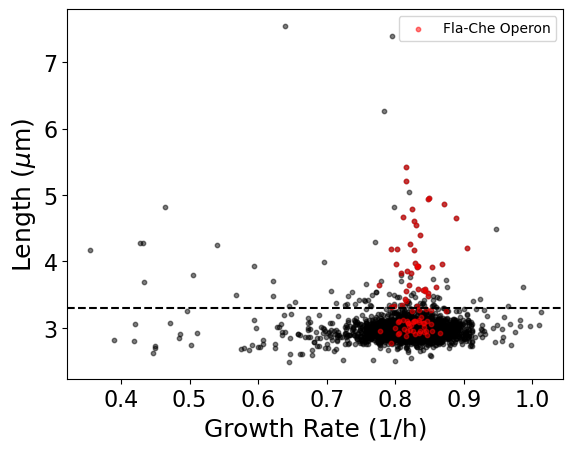

In [11]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')

df[df['Gene'].isin(fla_che_operon)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=10, label = 'Fla-Che Operon'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Length'] > 3.3, :]
 .assign(in_fla_che_operon = lambda df_: df_['Gene'].isin(fla_che_operon))
 .sort_values(by='Length', ascending=False)
 .head(20)
#  .to_csv('noness_long.csv', index=False)
)

#### Nonessentials - Reduced growth rate

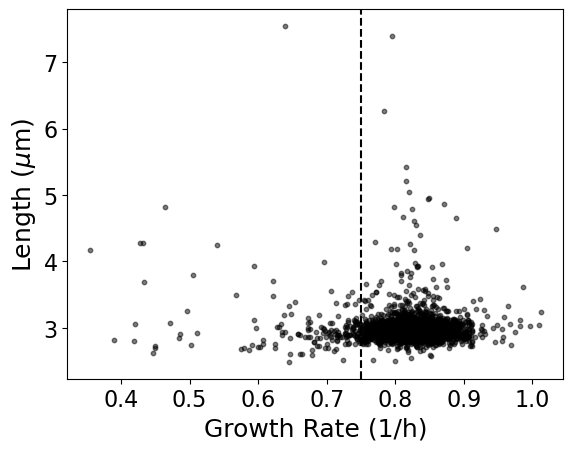

In [144]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
# _ = plt.axhline(3.3, color='black', linestyle='--')
_ = plt.axvline(0.75, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Growth Rate'] < 0.75, :]
 .sort_values(by='Growth Rate', ascending=True)
 .to_csv('noness_slow-growth.csv', index=False)
)

#### Nonessentials - Increased growth rate

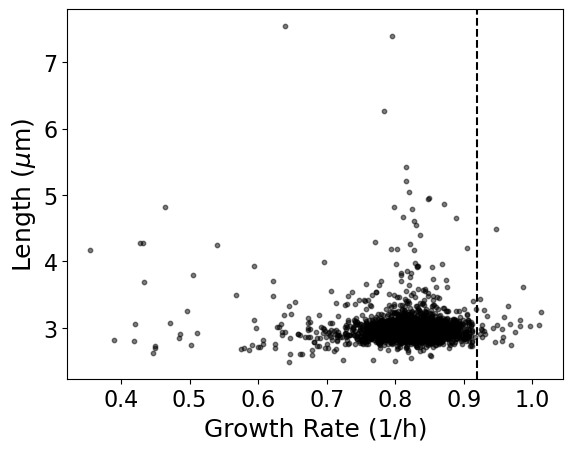

In [206]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
# _ = plt.axhline(3.3, color='black', linestyle='--')
_ = plt.axvline(0.92, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Growth Rate'] > 0.92, :]
 .sort_values(by='Growth Rate', ascending=False)
 .to_csv('noness_fast-growth.csv', index=False)
)

#### Nonessentials - Wide

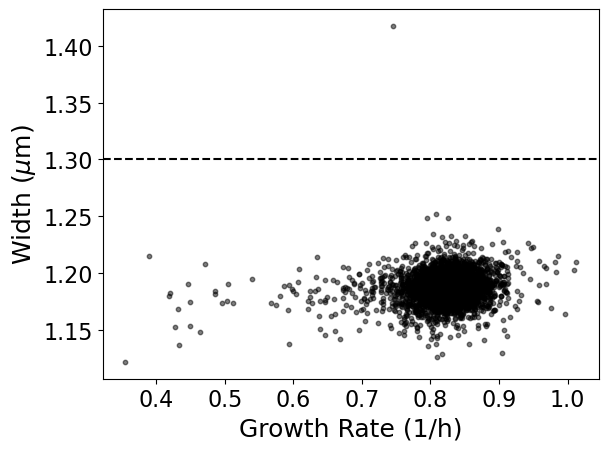

In [196]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Width'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(1.3, color='black', linestyle='--')
# _ = plt.axvline(0.75, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Width'] > 1.3, :]
 .sort_values(by='Width', ascending=False)
 .to_csv('noness_wide.csv', index=False)
)

#### Nonessentials - Aberrant Septum Displacement

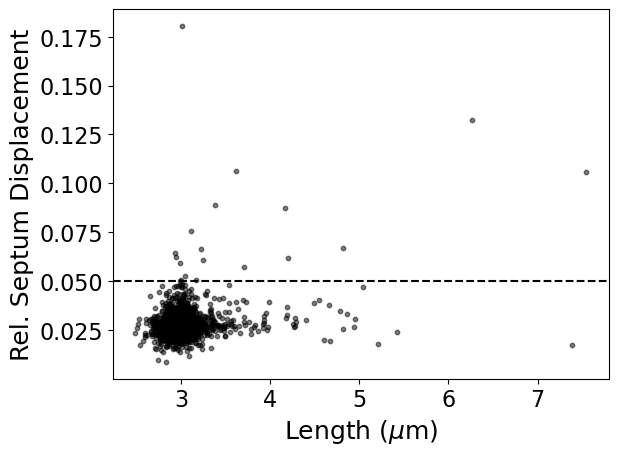

In [202]:
df = df_10
x_var = 'Length'
y_var = 'Septum Displacement Length Normalized'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(0.05, color='black', linestyle='--')
# _ = plt.axvline(0.75, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Septum Displacement Length Normalized'] > 0.05, :]
 .sort_values(by='Septum Displacement Length Normalized', ascending=False)
 .to_csv('noness_div-pos.csv', index=False)
)

### Essentials

#### Essentials - All

In [225]:
df = df_8

(df
#  .loc[(df['Length'] > 3.3) & (df['Growth Rate'] > 0.8), :]
#  .sort_values(by='Length', ascending=False)
 .to_csv('ess_ALL.csv', index=False)
)

#### Essentials - Long, Normal Growth Rate

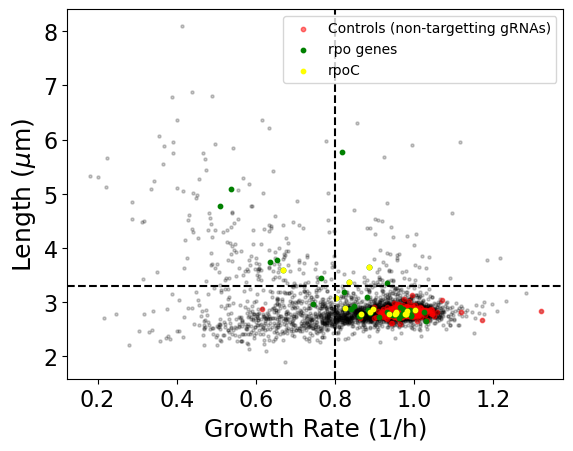

In [23]:
df = df_8
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.2, ax=ax, color='black',
        # Set marker size to 1
        s=5,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')
_ = plt.axvline(0.8, color='black', linestyle='--')

df[df['Category'] == 'control'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=10, label = 'Controls (non-targetting gRNAs)'
        )

df_8[df_8['Gene'].str.contains('rpo')].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='green',
        # Set marker size to 1
        s=10, label = 'rpo genes'
        )

df_8[df_8['Gene'] == 'rpoC'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='yellow',
        # Set marker size to 1
        s=10, label = 'rpoC'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[(df['Length'] > 3.3) & (df['Growth Rate'] > 0.8), :]
 .sort_values(by='Length', ascending=False)
 .to_csv('ess_long-normalGrowth.csv', index=False)
)

In [16]:
df_8[df_8['Gene'] == 'rpoC']

,opLAG1_id,mCherry mean_intensity,Length,Width,Growth Rate,Interdivision Time (s),Septum Displacement Length Normalized,sgRNA,locus_tag,Gene,Predicted_Efficacy,Category,TargetID,N Observations
466,578,1322.621111,2.792351,1.313420,0.954193,2493.280482,0.027882,ATACCAAATGTGGGAAACTT,BSU_01080,rpoC,0.086198,essential,190,23
467,579,1154.479085,2.786788,1.321849,0.977298,2648.934797,0.028382,ATACCAAATGTGGGAAACTC,BSU_01080,rpoC,0.031383,essential,190,14
468,580,1743.636857,2.773720,1.297684,0.866835,2550.130999,0.023763,ATACCAAATGTGGGAAACTA,BSU_01080,rpoC,0.129656,essential,190,7
469,581,1098.520523,2.787057,1.320554,0.950888,2683.409058,0.026126,GTGTTACTTCGACTCCGCAC,BSU_01080,rpoC,0.140822,essential,191,20
470,582,1261.261353,2.832039,1.296226,0.983386,2550.595063,0.031272,TGACATTCCCAGTCCTTAGA,BSU_01080,rpoC,0.227855,essential,192,23
471,583,1098.904565,2.861984,1.318372,1.003547,2599.989300,0.027171,TGACATTCCCAGTCCTTAAT,BSU_01080,rpoC,0.281530,essential,192,13
472,584,1388.643150,2.823815,1.311212,0.955450,2453.170140,0.022254,TGACATTCCCAGTACTTAGT,BSU_01080,rpoC,0.397341,essential,192,12
473,585,1716.964529,2.789388,1.313486,0.937528,2604.977125,0.028034,AGCACAAGACCCATACGGGT,BSU_01080,rpoC,0.455622,essential,193,14
474,586,1177.118193,2.779604,1.311558,0.979540,2600.226427,0.030471,TGTGCCCCATTCTATCACGA,BSU_01080,rpoC,0.470301,essential,194,61
475,587,2435.092426,2.891941,1.308221,0.824904,2550.148541,0.029145,TGACATTCCCAGTCCATAGT,BSU_01080,rpoC,0.552255,essential,192,8


#### Essentials - Long, Reduced Growth Rate

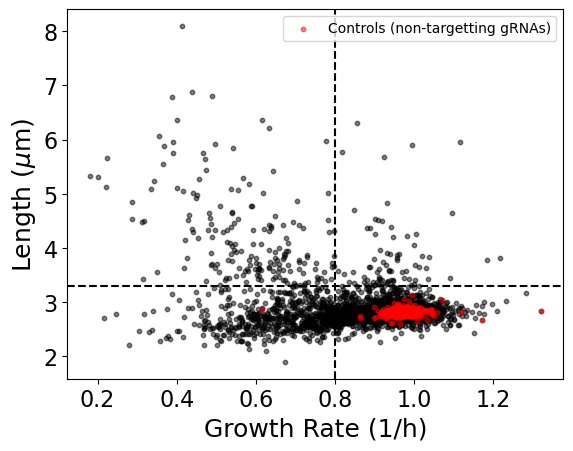

In [224]:
df = df_8
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')
_ = plt.axvline(0.8, color='black', linestyle='--')

df[df['Category'] == 'control'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=10, label = 'Controls (non-targetting gRNAs)'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[(df['Length'] > 3.3) & (df['Growth Rate'] < 0.8), :]
 .sort_values(by='Length', ascending=False)
 .to_csv('ess_long-reducedGrowth.csv', index=False)
)

#### Essentials - Wide

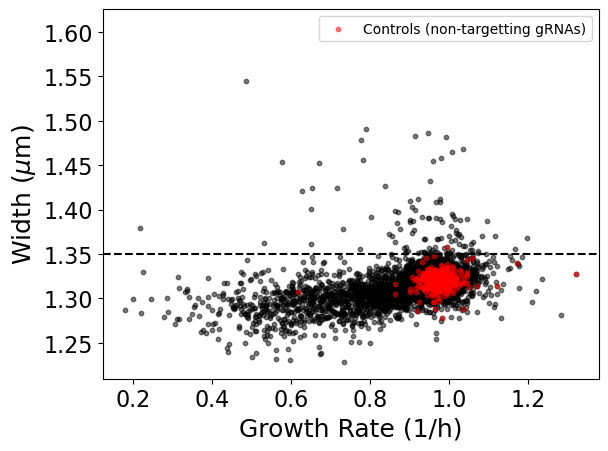

In [217]:
df = df_8
x_var = 'Growth Rate'
y_var = 'Width'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

df[df['Category'] == 'control'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=10, label = 'Controls (non-targetting gRNAs)'
        )


#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(1.35, color='black', linestyle='--')
# _ = plt.axvline(0.75, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Width'] > 1.35, :]
 .sort_values(by='Width', ascending=False)
 .to_csv('ess_wide.csv', index=False)
)

#### Essentials - Aberrant Septum Displacement

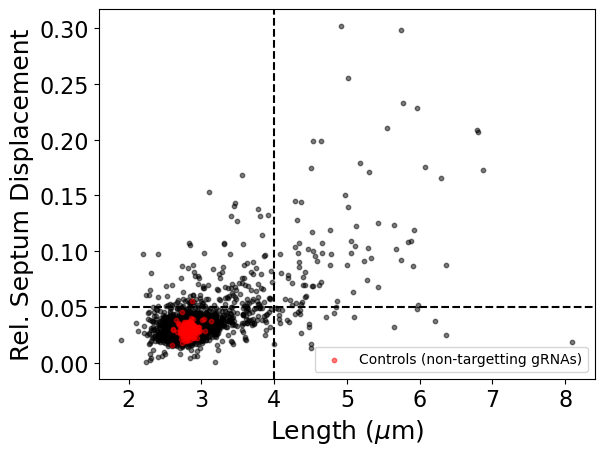

In [223]:
df = df_8
x_var = 'Length'
y_var = 'Septum Displacement Length Normalized'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

df[df['Category'] == 'control'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=10, label = 'Controls (non-targetting gRNAs)'
        )


#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(0.05, color='black', linestyle='--')
_ = plt.axvline(4, color='black', linestyle='--')

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[(df['Septum Displacement Length Normalized'] > 0.05) & (df['Length'] < 4), :]
 .sort_values(by='Septum Displacement Length Normalized', ascending=False)
 .to_csv('ess_divPos-NormalLength.csv', index=False)
)

### Other

#### Transcription - Essentials

In [25]:
rna_pol = ["rpoA", "rpoB", "rpoC", "rpoE", "rpoY", "yloH"]
txn_elongation_termination = ["greA", "mfd", "nusA", "nusB", "nusG", "rho"]
sigma_factors = [
    "SigA",
    "SigB",
    "SigD",
    "SigE",
    "SigF",
    "SigG",
    "SigH",
    "SigI",
    "SigK",
    "SigL",
    "SigM",
    "SigV",
    "SigW",
    "SigX",
    "SigY",
    "SigZ",
    "Xpf",
    "YlaC",
    "SigO-RsoA"
]

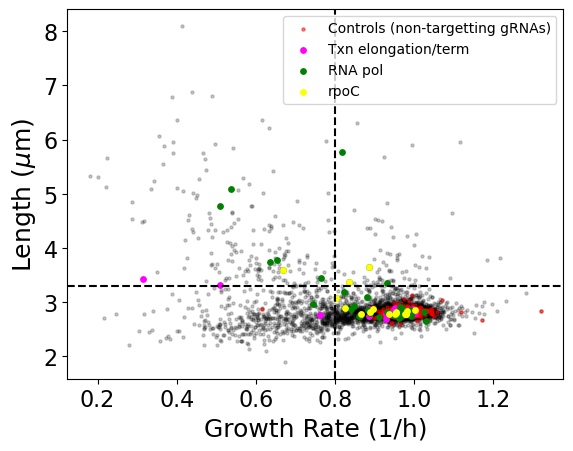

In [32]:
df = df_8
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.2, ax=ax, color='black',
        # Set marker size to 1
        s=5,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')
_ = plt.axvline(0.8, color='black', linestyle='--')

df[df['Category'] == 'control'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='red',
        # Set marker size to 1
        s=5, label = 'Controls (non-targetting gRNAs)'
        )

df_8[df_8['Gene'].isin(txn_elongation_termination)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='magenta',
        # Set marker size to 1
        s=15, label = 'Txn elongation/term'
        )

df_8[df_8['Gene'].isin(rna_pol)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='green',
        # Set marker size to 1
        s=15, label = 'RNA pol'
        )

df_8[df_8['Gene'] == 'rpoC'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='yellow',
        # Set marker size to 1
        s=15, label = 'rpoC'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[(df['Length'] > 3.3) & (df['Growth Rate'] > 0.8), :]
 .sort_values(by='Length', ascending=False)
 .to_csv('ess_long-normalGrowth.csv', index=False)
)

#### Fla-Che operon - Nonessentials

In [12]:
fla_che_operon_start = ['flgB', 'flgC', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ']# 'ylxF', 'fliK', 'flgD', 'flgE', 'fliL', 'fliM', 'fliY'
# , 'cheY', 'fliZ', 'fliP', 'fliQ', 'fliR', 'flhB', 'flhA', 'flhF', 'flhG', 'cheB', 'cheA', 'cheW', 'cheC', 'cheD', 'sigD', 'swrB']
fla_che_operon_mid = ['ylxF', 'fliK', 'flgD', 'flgE', 'fliL', 'fliM', 'fliY', 'cheY', 'fliZ', 'fliP', 'fliQ', 'fliR']
fla_che_operon_end = ['flhB', 'flhA', 'flhF', 'flhG', 'cheB', 'cheA', 'cheW', 'cheC', 'cheD', 'sigD', 'swrB']

fla_che_operon = fla_che_operon_start + fla_che_operon_mid + fla_che_operon_end

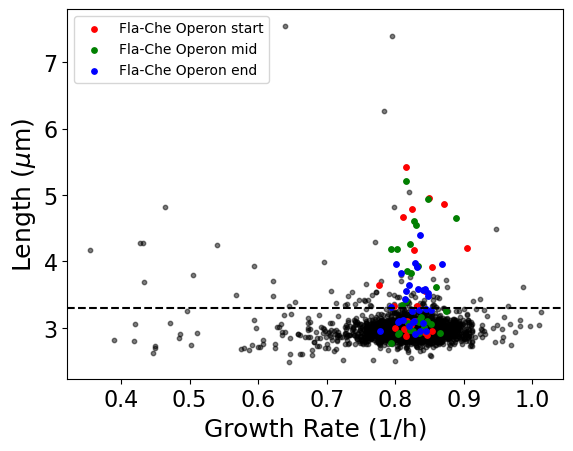

In [42]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')

df[df['Gene'].isin(fla_che_operon_start)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='red',
        # Set marker size to 1
        s=15, label = 'Fla-Che Operon start'
        )

df[df['Gene'].isin(fla_che_operon_mid)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='green',
        # Set marker size to 1
        s=15, label = 'Fla-Che Operon mid'
        )


df[df['Gene'].isin(fla_che_operon_end)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='blue',
        # Set marker size to 1
        s=15, label = 'Fla-Che Operon end'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

(df
 .loc[df['Length'] > 3.3, :]
 .assign(in_fla_che_operon = lambda df_: df_['Gene'].isin(fla_che_operon))
 .sort_values(by='Length', ascending=False)
 .to_csv('noness_long.csv', index=False)
)

#### Fla-Che operon length vs. position in operon

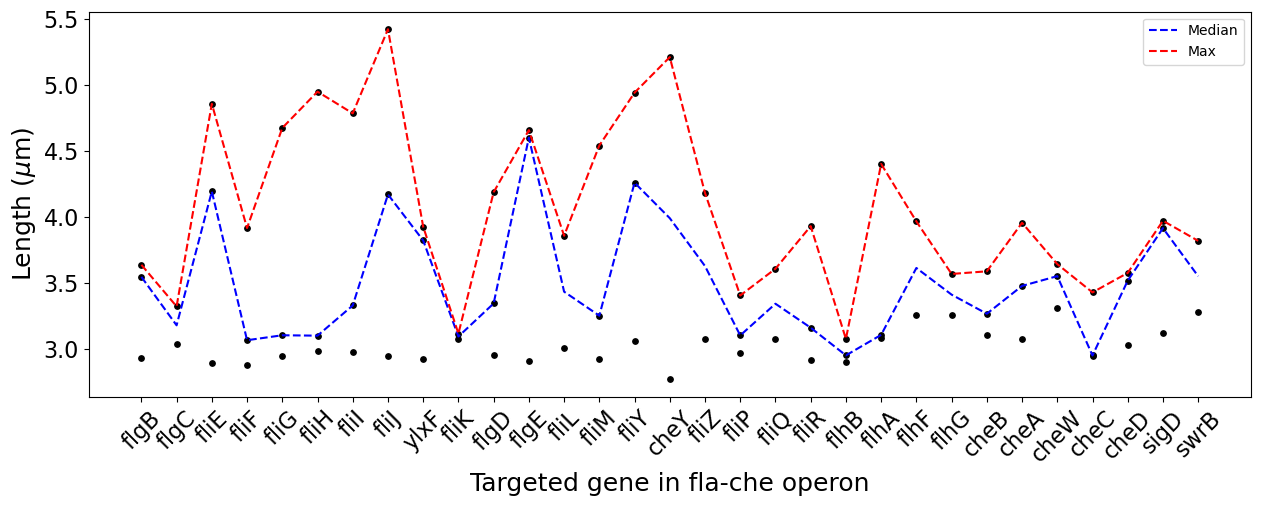

In [14]:
df = df_10
y_var = 'Length'

fig, ax = plt.subplots(figsize=(15, 5))
# Index in fla-Che operon
df = (df
              .loc[df['Gene'].isin(fla_che_operon), :]
              .assign(fla_che_index=lambda df_:df_['Gene'].apply(
                          lambda gene: fla_che_operon.index(gene) if gene in fla_che_operon else -1)
                     )
             )

x_var = 'fla_che_index'

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='black',
        # Set marker size to 1
        s=15,
        )

# Mean and median
# df_mean = df.groupby('fla_che_index')['Length'].mean().to_frame().reset_index()
df_median = df.groupby('fla_che_index')['Length'].median().to_frame().reset_index()
df_max = df.groupby('fla_che_index')['Length'].max().to_frame().reset_index()

# df_mean.plot(x=x_var, y=y_var,
#         alpha=1, ax=ax, color='red', linestyle='--', label = 'Mean',
#         # Set marker size to 1
#         #s=15,
#         )

df_median.plot(x=x_var, y=y_var,
        alpha=1, ax=ax, color='blue', linestyle='--', label = 'Median'
        # Set marker size to 1
        #s=15,
        )

df_max.plot(x=x_var, y=y_var,
        alpha=1, ax=ax, color='red', linestyle='--', label = 'Max',
        # Set marker size to 1
        #s=15,
        )

# Get the current tick locations
tick_locations = np.arange(len(fla_che_operon))
tick_labels = fla_che_operon
ax.set_xticks(tick_locations)
ax.set_xticklabels(tick_labels)

_ = plt.xticks(size=16, rotation=45)
_ = plt.yticks(size=16)

_ = plt.xlabel('Targeted gene in fla-che operon', size = 18)
_ = plt.ylabel(labels[y_var], size = 18)

#### DegU regulon

In [50]:
degU_reg_act = ['aprE', 'bpr', 'bslA', 'capA', 'capB', 'capC', 'capE', 'comK', 'degQ', 'degU', 'epr', 'flgB', 'flgC', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'ylxF', 'fliK', 'flgD', 'flgE', 'fliL', 'fliM', 'fliY', 'cheY', 'fliZ', 'fliP', 'fliQ', 'fliR', 'flhB', 'flhA', 'flhF', 'flhG', 'cheB', 'cheA', 'cheW', 'cheC', 'cheD', 'sigD', 'swrB', 'flgM', 'flgN', 'flgK', 'flgL', 'levB', 'sacB', 'sipT', 'swrAA', 'minJ', 'tkmA', 'ptkA', 'ptpZ', 'ugd', 'ycdA', 'yukE', 'yukD', 'yukC', 'yukB', 'yueB', 'yueC', 'yvcA', 'yvcB', 'yveA', 'yvzA']
degU_reg_rep = ['flgB', 'flgC', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'ylxF', 'fliK', 'flgD', 'flgE', 'fliL', 'fliM', 'fliY', 'cheY', 'fliZ', 'fliP', 'fliQ', 'fliR', 'flhB', 'flhA', 'flhF', 'flhG', 'cheB', 'cheA', 'cheW', 'cheC', 'cheD', 'sigD', 'swrB', 'wapA', 'wapI', 'yxjI', 'yxjJ']

In [51]:
degU_act_noFla = [gene for gene in degU_reg_act if gene not in fla_che_operon]
degU_rep_noFla = [gene for gene in degU_reg_rep if gene not in fla_che_operon]

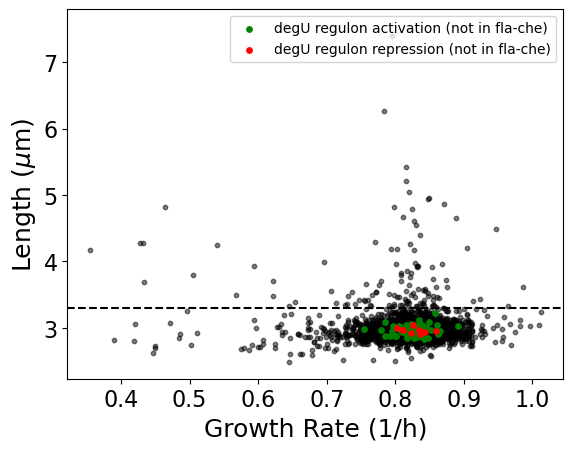

In [111]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')

df[df['Gene'].isin(degU_act_noFla)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='green',
        # Set marker size to 1
        s=15, label = 'degU regulon activation (not in fla-che)'
        )

df[df['Gene'].isin(degU_rep_noFla)].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='red',
        # Set marker size to 1
        s=15, label = 'degU regulon repression (not in fla-che)'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)


In [ ]:
degSU = ['degS', 'degU']

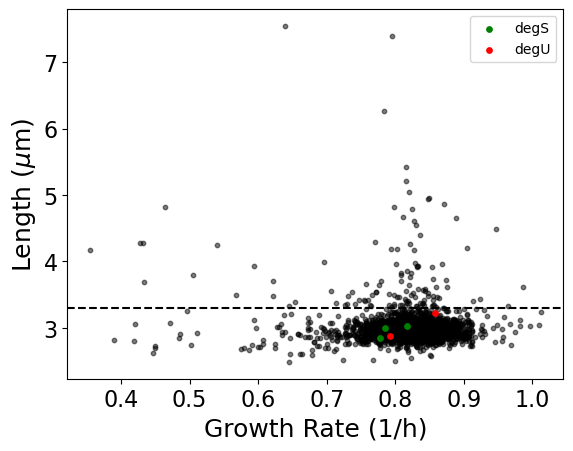

In [13]:
df = df_10
x_var = 'Growth Rate'
y_var = 'Length'

fig, ax = plt.subplots()

df.plot(x=x_var, y=y_var,
        kind='scatter', alpha=0.5, ax=ax, color='black',
        # Set marker size to 1
        s=10,
        )

#####
# Plot horizontal dashed line at 3.5
_ = plt.axhline(3.3, color='black', linestyle='--')

df[df['Gene'] == 'degS'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='green',
        # Set marker size to 1
        s=15, label = 'degS'
        )

df[df['Gene']=='degU'].plot(x=x_var, y=y_var,
        kind='scatter', alpha=1, ax=ax, color='red',
        # Set marker size to 1
        s=15, label = 'degU'
        )

_ = plt.xticks(size=16)
_ = plt.yticks(size=16)

_ = plt.xlabel(labels[x_var], size = 18)
_ = plt.ylabel(labels[y_var], size = 18)
